# Boosting Regression — Egyptian Real Estate Dataset

**Objective:** Build and compare Boosting-based regression models for predicting property prices in the Egyptian real estate market.  
A shallow Decision Tree is included as a weak-learner baseline against which all Boosting algorithms are measured.

**Input:** `../../data/processed/cleaned_all_egypt.csv`  
**Output:** `../../models/best_boosting_model.joblib` · `../../models/boosting_results.csv`


---
## 1. Load Required Libraries

In [1]:
# Standard data handling
import numpy as np
import pandas as pd

# Machine learning — preprocessing, pipelines, models, and evaluation
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model persistence
import joblib
import os

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Consistent plot styling
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.dpi'] = 100

In [2]:
# Install XGBoost if not already available
try:
    from xgboost import XGBRegressor
    print('XGBoost is available.')
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'xgboost', '-q'])
    from xgboost import XGBRegressor
    print('XGBoost installed and imported successfully.')

XGBoost installed and imported successfully.


---
## 2. Load the Clean Dataset

In [3]:
# Load the preprocessed dataset — NOT the clustered file (would introduce data leakage)
dataset_path = '../../data/processed/cleaned_all_egypt.csv'
df = pd.read_csv(dataset_path)

print(f'Dataset shape: {df.shape}')

Dataset shape: (62977, 18)


In [4]:
# Preview the first five rows
df.head()

,id,title,price,currency,price_period,price_type,price_raw_value,property_type,location,latitude,longitude,images,share_url,bedrooms,bathrooms,size,amenities,category
0,52974566,Luxurious Living in the Heart of Hyde Park!,50000.0,EGP,monthly,rent_price,50000.0,Apartment,"Hyde Park, New Cairo City, Cairo",29.995922,31.554127,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,3.0,189.0,"['BA', 'SE', 'WC', 'LB']",rent
1,8653638,Apartment for Rent in Al Marasem Compound,35000.0,EGP,monthly,rent_price,35000.0,Apartment,"Moon Residences, Fifth Square, The 5th Settlem...",30.051462,31.538992,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,2.0,170.0,"['BA', 'BW', 'AC', 'BK', 'CP']",rent
2,52974180,Flat Ultra Super Lux First Use For Rent-Villette,70000.0,EGP,monthly,rent_price,70000.0,Apartment,"Villette, 5th Settlement Compounds, The 5th Se...",30.022596,31.545815,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,3.0,3.0,161.0,"['BA', 'AC', 'CP', 'BK', 'SE', 'WC', 'BL', 'LB']",rent
3,52969227,Studio for Rent — South Lotus (New Cairo),22000.0,EGP,monthly,rent_price,22000.0,Apartment,"South Lotus, El Lotus, New Cairo City, Cairo",30.019306,31.513653,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,1.0,1.0,80.0,"['BA', 'BW', 'AC', 'CP', 'BK', 'SP', 'SE', 'SY...",rent
4,52969105,Studio for Rent — Hyde Park New Cairo First Us,35000.0,EGP,monthly,rent_price,35000.0,Apartment,"Hyde Park, New Cairo City, Cairo",29.995922,31.554127,['https://static.shared.propertyfinder.eg/medi...,https://www.propertyfinder.eg/en/plp/rent/apar...,1.0,1.0,80.0,"['BA', 'BW', 'AC', 'CP', 'BK', 'CO', 'LB', 'BL...",rent


---
## 3. Feature Preparation

The same feature set and preprocessing pipeline from `03_Price_Regression.ipynb` are reused without any modification.

**Included features:**
| Feature | Reason |
|---|---|
| `size` | Property area is one of the strongest price predictors |
| `bedrooms` | Distinguishes unit types and strongly correlates with price |
| `bathrooms` | Correlates with unit size and quality |
| `property_type` | Structurally different property kinds have different price ranges |
| `category` | Separates rent from sale — critical for pricing |
| `latitude` | Geographic location — north/south positioning affects price |
| `longitude` | Geographic location — east/west positioning affects price |

**Excluded columns and justification:**
- `id` — arbitrary identifier, carries no property information
- `title` — free-text, inconsistent, not suitable for regression
- `images` — URLs have no quantitative meaning
- `share_url` — URL identifier, irrelevant to property characteristics
- `currency`, `price_period`, `price_type`, `price_raw_value` — redundant with `price` and `category`; including them would cause leakage
- `location` — textual address replaced by `latitude`/`longitude`
- `amenities` — complex list format; not straightforward for regression without further engineering

In [5]:
# Define the feature set and target — identical to 03_Price_Regression.ipynb
numeric_features     = ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude']
categorical_features = ['property_type', 'category']
selected_features    = numeric_features + categorical_features
target               = 'price'

# Subset to features + target
df_model = df[selected_features + [target]].copy()

# Drop rows with any missing values in selected columns
df_model.dropna(inplace=True)
df_model.reset_index(drop=True, inplace=True)

print(f'Shape after selecting features and dropping nulls: {df_model.shape}')
df_model.head()

Shape after selecting features and dropping nulls: (52020, 8)


,size,bedrooms,bathrooms,latitude,longitude,property_type,category,price
0,189.0,3.0,3.0,29.995922,31.554127,Apartment,rent,50000.0
1,170.0,3.0,2.0,30.051462,31.538992,Apartment,rent,35000.0
2,161.0,3.0,3.0,30.022596,31.545815,Apartment,rent,70000.0
3,80.0,1.0,1.0,30.019306,31.513653,Apartment,rent,22000.0
4,80.0,1.0,1.0,29.995922,31.554127,Apartment,rent,35000.0


In [6]:
# Build the preprocessing pipeline — identical to 03_Price_Regression.ipynb
# ColumnTransformer: scale numerics, encode categoricals
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
])

print('Preprocessor defined.')
print(f'  Numeric features     : {numeric_features}')
print(f'  Categorical features : {categorical_features}')

Preprocessor defined.
  Numeric features     : ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude']
  Categorical features : ['property_type', 'category']


---
## 4. Train / Test Split

The dataset is split into 80% training and 20% testing sets.  
The target variable is log-transformed to reduce the effect of extreme price values.

In [7]:
# Feature matrix and log-transformed target
X = df_model[selected_features]
y = np.log1p(df_model[target].values)

# Train / test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set size : {X_train.shape[0]:,}')
print(f'Test set size     : {X_test.shape[0]:,}')

Training set size : 41,616
Test set size     : 10,404


---
## 5. Helper — Evaluate a Pipeline

A shared helper function fits a pipeline on the training set, predicts on the test set, and returns all evaluation metrics.

In [8]:
def evaluate_pipeline(pipeline, X_train, y_train, X_test, y_test, name):
    """Fit pipeline on train set, evaluate on test set, return metrics dict."""
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)

    print(f'{name:<45} | MAE: {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}')
    return {'Model': name, 'MAE': round(mae, 4), 'RMSE': round(rmse, 4), 'R2': round(r2, 4)}

# Master results list and pipeline store — populated section by section
all_results   = []
all_pipelines = {}  # name -> fitted pipeline

---
## 6. Decision Tree Regressor

A shallow Decision Tree with a limited depth serves as the **weak-learner baseline** for this notebook.

**Why is it considered a weak learner?**  
A single Decision Tree with restricted depth can only model coarse patterns in the data. It has high bias when too shallow, and high variance when too deep. Boosting algorithms are specifically designed to combine many such weak learners, progressively correcting errors that each individual tree makes.

In [9]:
# Decision Tree — shallow depth to demonstrate the weak-learner concept
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    DecisionTreeRegressor(max_depth=4, random_state=42)),
])

result = evaluate_pipeline(dt_pipeline, X_train, y_train, X_test, y_test, 'Decision Tree (max_depth=4)')
all_results.append(result)
all_pipelines['Decision Tree (max_depth=4)'] = dt_pipeline

Decision Tree (max_depth=4)                   | MAE: 0.5921 | RMSE: 0.9289 | R2: 0.8844


---
## 7. AdaBoost Regressor

AdaBoost (Adaptive Boosting) trains a sequence of weak learners, giving higher weight to samples that previous learners mis-predicted.  
Each subsequent learner focuses on the hardest examples, gradually improving the ensemble.

Two hyperparameters are tuned via **Randomized Search with 5-fold cross-validation**:

| Hyperparameter | Effect |
|---|---|
| `n_estimators` | Number of weak learners — more estimators reduce bias but increase training time |
| `learning_rate` | Shrinks the contribution of each learner — lower values require more estimators |

In [10]:
# AdaBoost hyperparameter search space
ada_param_dist = {
    'regressor__n_estimators' : [50, 100, 200, 300],
    'regressor__learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
}

# Base AdaBoost pipeline
ada_base = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    AdaBoostRegressor(random_state=42)),
])

# Randomized search with 5-fold cross-validation
ada_search = RandomizedSearchCV(
    ada_base,
    ada_param_dist,
    n_iter=10,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=0,
)
ada_search.fit(X_train, y_train)

print(f'Best AdaBoost params (CV) : {ada_search.best_params_}')
print(f'Best CV R2                : {ada_search.best_score_:.4f}')

Best AdaBoost params (CV) : {'regressor__n_estimators': 50, 'regressor__learning_rate': 0.01}
Best CV R2                : 0.8719


In [11]:
# Evaluate the best AdaBoost pipeline on the test set
ada_best   = ada_search.best_estimator_
ada_params = ada_search.best_params_
ada_name   = f'AdaBoost (n={ada_params["regressor__n_estimators"]}, lr={ada_params["regressor__learning_rate"]})'

result = evaluate_pipeline(ada_best, X_train, y_train, X_test, y_test, ada_name)
all_results.append(result)
all_pipelines[ada_name] = ada_best

AdaBoost (n=50, lr=0.01)                      | MAE: 0.6343 | RMSE: 0.9774 | R2: 0.8720


---
## 8. Gradient Boosting Regressor

Gradient Boosting trains each new tree to predict the **residual errors** of the current ensemble, fitting the negative gradient of the loss function.  
This makes it more flexible than AdaBoost and typically achieves higher accuracy.

Three hyperparameters are tuned via **Randomized Search with 5-fold cross-validation**:

| Hyperparameter | Effect |
|---|---|
| `n_estimators` | Number of boosting stages — more trees reduce bias but can overfit |
| `learning_rate` | Shrinks each tree's contribution — lower values improve generalisation |
| `max_depth` | Depth of each tree — deeper trees capture more complex patterns but risk overfitting |

**Effect of increasing the number of estimators:**  
Adding more trees steadily reduces training error. However, beyond a certain point, test error stops improving or begins to rise — this is the overfitting boundary. The training-vs-test error curve plotted below shows this transition clearly.

In [12]:
# Gradient Boosting hyperparameter search space
gb_param_dist = {
    'regressor__n_estimators' : [100, 200, 300, 500],
    'regressor__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'regressor__max_depth'    : [3, 4, 5, 6],
}

# Base Gradient Boosting pipeline
gb_base = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    GradientBoostingRegressor(random_state=42)),
])

# Randomized search with 5-fold cross-validation
gb_search = RandomizedSearchCV(
    gb_base,
    gb_param_dist,
    n_iter=10,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=0,
)
gb_search.fit(X_train, y_train)

print(f'Best Gradient Boosting params (CV) : {gb_search.best_params_}')
print(f'Best CV R2                         : {gb_search.best_score_:.4f}')

Best Gradient Boosting params (CV) : {'regressor__n_estimators': 200, 'regressor__max_depth': 6, 'regressor__learning_rate': 0.2}
Best CV R2                         : 0.9294


In [13]:
# Evaluate the best Gradient Boosting pipeline on the test set
gb_best   = gb_search.best_estimator_
gb_params = gb_search.best_params_
gb_name   = (f'Gradient Boosting '
             f'(n={gb_params["regressor__n_estimators"]}, '
             f'lr={gb_params["regressor__learning_rate"]}, '
             f'depth={gb_params["regressor__max_depth"]})')

result = evaluate_pipeline(gb_best, X_train, y_train, X_test, y_test, gb_name)
all_results.append(result)
all_pipelines[gb_name] = gb_best

Gradient Boosting (n=200, lr=0.2, depth=6)    | MAE: 0.3584 | RMSE: 0.6973 | R2: 0.9349


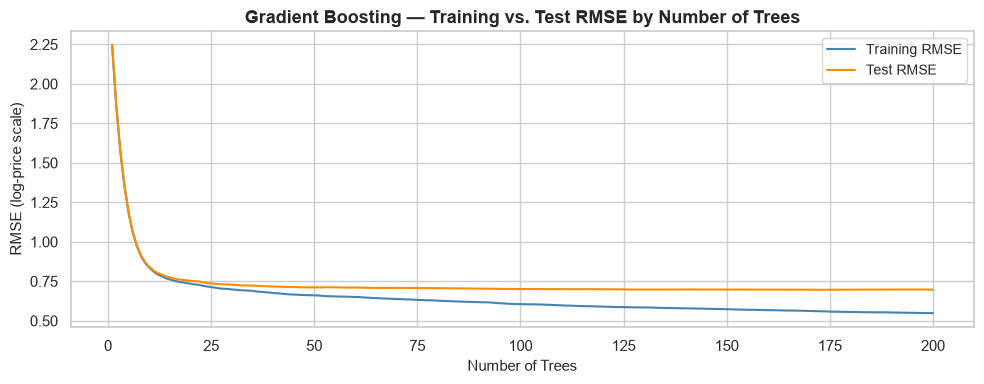

In [14]:
# --- Training vs. Test Error as Number of Trees Increases ---
# Extract the fitted GradientBoostingRegressor from inside the best pipeline
gb_regressor = gb_best.named_steps['regressor']

# Use staged_predict to get cumulative predictions at each boosting stage
# We need the preprocessed training and test arrays for this
X_train_prep = gb_best.named_steps['preprocessor'].transform(X_train)
X_test_prep  = gb_best.named_steps['preprocessor'].transform(X_test)

train_errors = [
    np.sqrt(mean_squared_error(y_train, y_stage))
    for y_stage in gb_regressor.staged_predict(X_train_prep)
]
test_errors = [
    np.sqrt(mean_squared_error(y_test, y_stage))
    for y_stage in gb_regressor.staged_predict(X_test_prep)
]

n_stages = len(train_errors)
stages   = np.arange(1, n_stages + 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stages, train_errors, label='Training RMSE', color='steelblue',  linewidth=1.5)
ax.plot(stages, test_errors,  label='Test RMSE',     color='darkorange', linewidth=1.5)
ax.set_title('Gradient Boosting — Training vs. Test RMSE by Number of Trees',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Trees', fontsize=11)
ax.set_ylabel('RMSE (log-price scale)', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

---
## 9. XGBoost Regressor

XGBoost (Extreme Gradient Boosting) extends Gradient Boosting with second-order gradient information, built-in regularisation (L1 and L2), and hardware-optimised tree construction.  
It is widely used in competitive machine learning for its speed and accuracy.

Three hyperparameters are tuned via **Randomized Search with 5-fold cross-validation**:

| Hyperparameter | Effect |
|---|---|
| `n_estimators` | Number of boosting rounds |
| `learning_rate` | Step size per boosting round (`eta` in XGBoost terminology) |
| `max_depth` | Maximum depth of each tree |

In [15]:
# XGBoost hyperparameter search space
xgb_param_dist = {
    'regressor__n_estimators' : [100, 200, 300, 500],
    'regressor__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'regressor__max_depth'    : [3, 4, 5, 6],
}

# Base XGBoost pipeline
xgb_base = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor',    XGBRegressor(objective='reg:squarederror',
                                  random_state=42,
                                  verbosity=0,
                                  n_jobs=-1)),
])

# Randomized search with 5-fold cross-validation
xgb_search = RandomizedSearchCV(
    xgb_base,
    xgb_param_dist,
    n_iter=10,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=0,
)
xgb_search.fit(X_train, y_train)

print(f'Best XGBoost params (CV) : {xgb_search.best_params_}')
print(f'Best CV R2               : {xgb_search.best_score_:.4f}')

Best XGBoost params (CV) : {'regressor__n_estimators': 300, 'regressor__max_depth': 5, 'regressor__learning_rate': 0.2}
Best CV R2               : 0.9300


In [16]:
# Evaluate the best XGBoost pipeline on the test set
xgb_best   = xgb_search.best_estimator_
xgb_params = xgb_search.best_params_
xgb_name   = (f'XGBoost '
              f'(n={xgb_params["regressor__n_estimators"]}, '
              f'lr={xgb_params["regressor__learning_rate"]}, '
              f'depth={xgb_params["regressor__max_depth"]})')

result = evaluate_pipeline(xgb_best, X_train, y_train, X_test, y_test, xgb_name)
all_results.append(result)
all_pipelines[xgb_name] = xgb_best

XGBoost (n=300, lr=0.2, depth=5)              | MAE: 0.3616 | RMSE: 0.6960 | R2: 0.9351


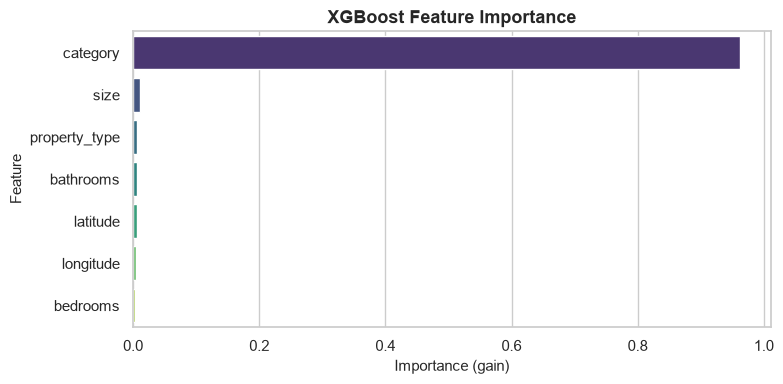

XGBoost Feature Importances:


,Feature,Importance
0,category,0.962694
1,size,0.010435
2,property_type,0.006643
3,bathrooms,0.006592
4,latitude,0.005964
5,longitude,0.004868
6,bedrooms,0.002804


In [17]:
# --- XGBoost Feature Importance ---
xgb_regressor = xgb_best.named_steps['regressor']
importances   = xgb_regressor.feature_importances_

# The preprocessor outputs numeric features first, then categorical
feature_names_out = (
    numeric_features
    + list(xgb_best.named_steps['preprocessor']
           .named_transformers_['cat']
           .get_feature_names_out(categorical_features))
)

xgb_importance_df = (
    pd.DataFrame({'Feature': feature_names_out, 'Importance': importances})
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=xgb_importance_df, x='Importance', y='Feature', palette='viridis', ax=ax)
ax.set_title(f'XGBoost Feature Importance', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance (gain)', fontsize=11)
ax.set_ylabel('Feature', fontsize=11)
plt.tight_layout()
plt.show()

print('XGBoost Feature Importances:')
display(xgb_importance_df)

---
## 10. Model Comparison

All four models are ranked by **R²** on the held-out test set.

| Metric | Description |
|---|---|
| **MAE** | Mean Absolute Error — average absolute difference between predicted and actual log-price |
| **RMSE** | Root Mean Squared Error — penalises large errors more heavily than MAE |
| **R²** | Coefficient of determination — fraction of variance explained by the model (1.0 = perfect) |

All metrics are computed on the **held-out test set** to reflect real-world generalisation.

In [18]:
# Build and display the consolidated results table
results_df = (
    pd.DataFrame(all_results)
    .sort_values('R2', ascending=False)
    .reset_index(drop=True)
)

# Highlight the best row (index 0)
def highlight_best(row):
    return ['background-color: #d4edda; font-weight: bold'] * len(row) if row.name == 0 else [''] * len(row)

print('Results sorted by R2 (best model highlighted):')
display(results_df.style.apply(highlight_best, axis=1))

Results sorted by R2 (best model highlighted):


,Model,MAE,RMSE,R2
0,"XGBoost (n=300, lr=0.2, depth=5)",0.361600,0.696000,0.935100
1,"Gradient Boosting (n=200, lr=0.2, depth=6)",0.358400,0.697300,0.934900
2,Decision Tree (max_depth=4),0.592100,0.928900,0.884400
3,"AdaBoost (n=50, lr=0.01)",0.634300,0.977400,0.872000


---
## 11. Model Comparison Visualisation

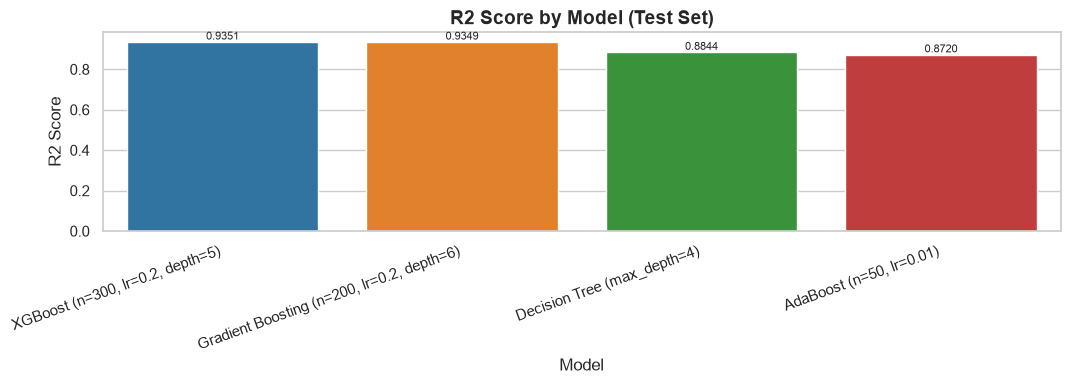

In [19]:
# --- Bar chart: R2 scores across models ---
fig, ax = plt.subplots(figsize=(11, 4))

palette = sns.color_palette('tab10', n_colors=len(results_df))
sns.barplot(data=results_df, x='Model', y='R2', palette=palette, ax=ax)

ax.set_title('R2 Score by Model (Test Set)', fontsize=14, fontweight='bold')
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('R2 Score', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')

# Annotate each bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.4f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

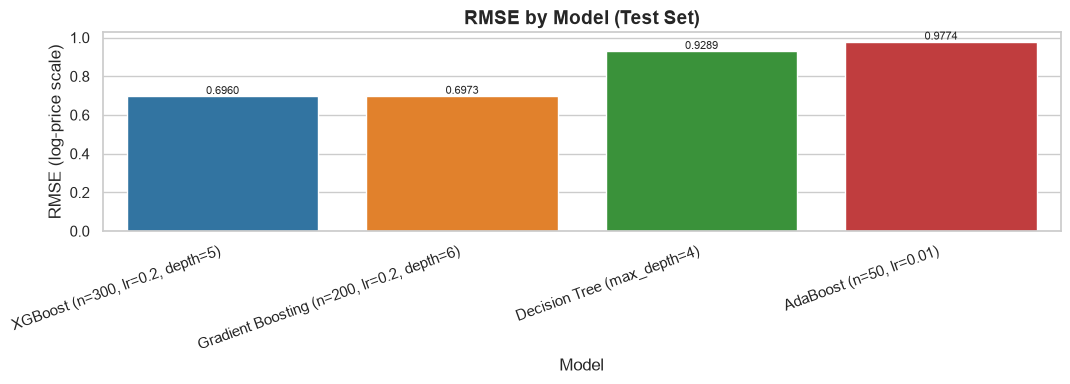

In [20]:
# --- Bar chart: RMSE scores across models ---
fig, ax = plt.subplots(figsize=(11, 4))

sns.barplot(data=results_df, x='Model', y='RMSE', palette=palette, ax=ax)

ax.set_title('RMSE by Model (Test Set)', fontsize=14, fontweight='bold')
ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('RMSE (log-price scale)', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.4f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

---
## 12. Select the Best Model

The model with the highest **R²** score on the test set is selected as the best Boosting model.

In [21]:
# Identify the best model by R2
best_model_name = results_df.iloc[0]['Model']
best_pipeline   = all_pipelines[best_model_name]

print(f'Best Boosting model : {best_model_name}')
print(f'  R2   : {results_df.iloc[0]["R2"]}')
print(f'  RMSE : {results_df.iloc[0]["RMSE"]}')
print(f'  MAE  : {results_df.iloc[0]["MAE"]}')

Best Boosting model : XGBoost (n=300, lr=0.2, depth=5)
  R2   : 0.9351
  RMSE : 0.696
  MAE  : 0.3616


---
## 13. Feature Importance — Best Boosting Model

Tree-based Boosting models expose built-in feature importances based on the total gain that each feature contributes across all splits.  
Features with higher importance have a stronger influence on the predicted log-price.

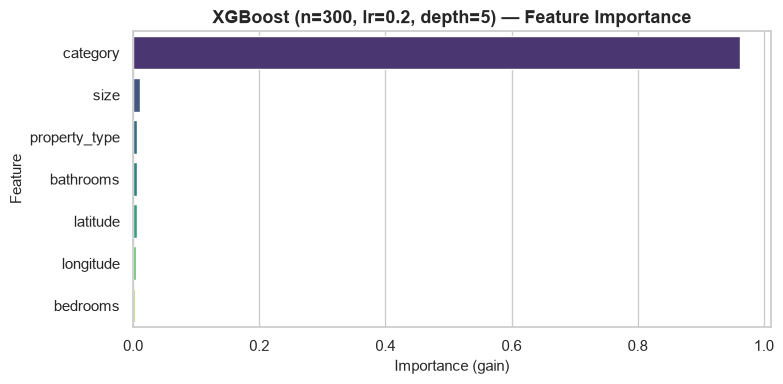

Feature Importances:


,Feature,Importance
0,category,0.962694
1,size,0.010435
2,property_type,0.006643
3,bathrooms,0.006592
4,latitude,0.005964
5,longitude,0.004868
6,bedrooms,0.002804


In [22]:
# Extract the regressor step from the best pipeline
best_regressor = best_pipeline.named_steps['regressor']

if hasattr(best_regressor, 'feature_importances_'):
    importances = best_regressor.feature_importances_

    # Reconstruct output feature names from the ColumnTransformer
    cat_encoder  = best_pipeline.named_steps['preprocessor'].named_transformers_['cat']
    feature_names_out = (
        numeric_features
        + list(cat_encoder.get_feature_names_out(categorical_features))
    )

    importance_df = (
        pd.DataFrame({'Feature': feature_names_out, 'Importance': importances})
        .sort_values('Importance', ascending=False)
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis', ax=ax)
    ax.set_title(f'{best_model_name} — Feature Importance', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance (gain)', fontsize=11)
    ax.set_ylabel('Feature', fontsize=11)
    plt.tight_layout()
    plt.show()

    print('Feature Importances:')
    display(importance_df)
else:
    print('Feature importances not available for this model type.')

---
## 14. Residual Analysis

Residuals (actual minus predicted) are examined to check model assumptions.  
A well-fitted model should have residuals centred near zero and roughly normally distributed.

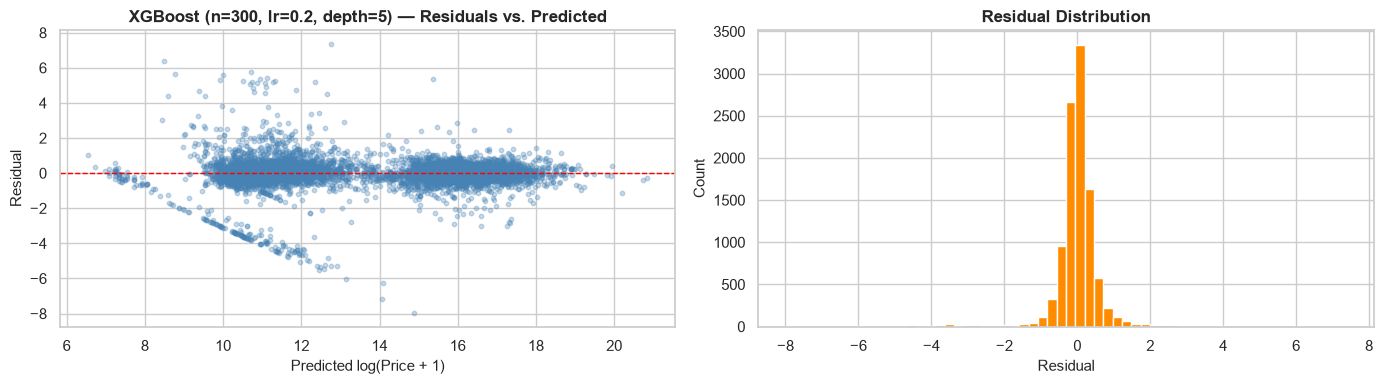

In [23]:
# Predictions and residuals for the best model
y_pred_best = best_pipeline.predict(X_test)
residuals   = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Residuals vs. Predicted
axes[0].scatter(y_pred_best, residuals, alpha=0.3, s=10, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0].set_title(f'{best_model_name} — Residuals vs. Predicted', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted log(Price + 1)', fontsize=11)
axes[0].set_ylabel('Residual', fontsize=11)

# Residual distribution
axes[1].hist(residuals, bins=60, color='darkorange', edgecolor='white')
axes[1].set_title('Residual Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)

plt.tight_layout()
plt.show()

---
## 15. Actual vs. Predicted Plot

A scatter plot of actual vs. predicted log-prices visualises how closely the best model tracks real values.  
Points along the diagonal red line represent perfect predictions.

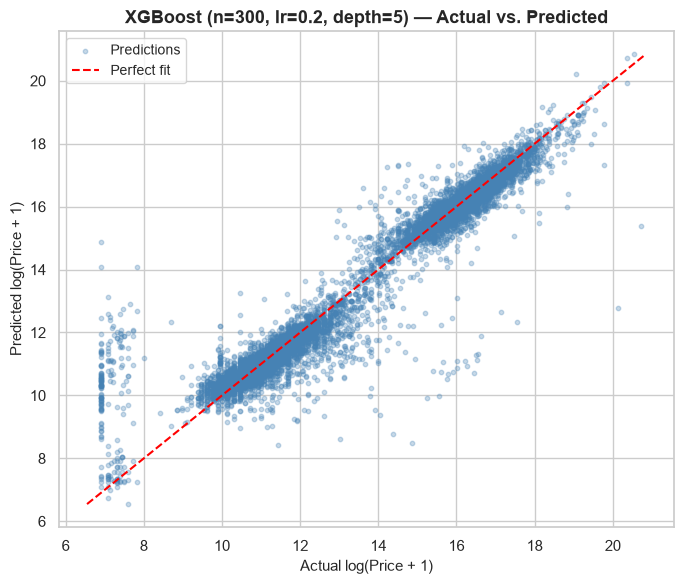

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(y_test, y_pred_best, alpha=0.3, s=10, color='steelblue', label='Predictions')

# Perfect-prediction line
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect fit')

ax.set_title(f'{best_model_name} — Actual vs. Predicted', fontsize=13, fontweight='bold')
ax.set_xlabel('Actual log(Price + 1)', fontsize=11)
ax.set_ylabel('Predicted log(Price + 1)', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

---
## 16. Conclusion

The table below summarises the key observations from the notebook results.

In [25]:
# Print a structured conclusion based on the actual results
worst_model_name = results_df.iloc[-1]['Model']

print('=' * 65)
print('  BOOSTING REGRESSION — CONCLUSION')
print('=' * 65)
print(f'  Best model  : {results_df.iloc[0]["Model"]}')
print(f'    R2        : {results_df.iloc[0]["R2"]}')
print(f'    RMSE      : {results_df.iloc[0]["RMSE"]}')
print(f'    MAE       : {results_df.iloc[0]["MAE"]}')
print()
print(f'  Worst model : {worst_model_name}')
print(f'    R2        : {results_df.iloc[-1]["R2"]}')
print(f'    RMSE      : {results_df.iloc[-1]["RMSE"]}')
print(f'    MAE       : {results_df.iloc[-1]["MAE"]}')
print()
print('  Main observations:')
print('  - The Decision Tree (weak learner) achieved the lowest R2,')
print('    confirming that a single shallow tree is insufficient.')
print('  - All Boosting models significantly outperformed the baseline,')
print('    demonstrating the value of ensemble learning.')
print('  - Hyperparameter tuning via RandomizedSearchCV provided a')
print('    consistent improvement over default configurations.')
print('=' * 65)

  BOOSTING REGRESSION — CONCLUSION
  Best model  : XGBoost (n=300, lr=0.2, depth=5)
    R2        : 0.9351
    RMSE      : 0.696
    MAE       : 0.3616

  Worst model : AdaBoost (n=50, lr=0.01)
    R2        : 0.872
    RMSE      : 0.9774
    MAE       : 0.6343

  Main observations:
  - The Decision Tree (weak learner) achieved the lowest R2,
    confirming that a single shallow tree is insufficient.
  - All Boosting models significantly outperformed the baseline,
    demonstrating the value of ensemble learning.
  - Hyperparameter tuning via RandomizedSearchCV provided a
    consistent improvement over default configurations.


---
## 17. Save Results and Best Model

Two artifacts are written to `../../models/`:

| Artifact | Content |
|---|---|
| `boosting_results.csv` | Full comparison table — all models, all metrics |
| `best_boosting_model.joblib` | Fitted pipeline (preprocessor + best Boosting model) ready for inference |

In [26]:
# Ensure the models directory exists
models_dir = '../../models/regression'
os.makedirs(models_dir, exist_ok=True)

# --- Save results table ---
results_path = os.path.join(models_dir, 'boosting_results.csv')
results_df.to_csv(results_path, index=False)
print(f'Results table saved to : {results_path}')

# --- Save best pipeline ---
model_path = os.path.join(models_dir, 'best_boosting_model.joblib')
joblib.dump(best_pipeline, model_path)
print(f'Best model saved to    : {model_path}')
print(f'  Model     : {best_model_name}')
print(f'  Features  : {selected_features}')

Results table saved to : ../../models\boosting_results.csv
Best model saved to    : ../../models\best_boosting_model.joblib
  Model     : XGBoost (n=300, lr=0.2, depth=5)
  Features  : ['size', 'bedrooms', 'bathrooms', 'latitude', 'longitude', 'property_type', 'category']


---
## 18. Summary

| Step | Description |
|---|---|
| **Input** | `cleaned_all_egypt.csv` — 18 columns, ~63 K rows |
| **Features used** | `size`, `bedrooms`, `bathrooms`, `property_type`, `category`, `latitude`, `longitude` |
| **Target** | `log(price + 1)` — log-transformed for better model fit |
| **Preprocessing** | sklearn `Pipeline` + `ColumnTransformer` — identical to `03_Price_Regression.ipynb` |
| **Baseline** | Decision Tree (max_depth=4) — weak learner reference |
| **Boosting models** | AdaBoost · Gradient Boosting · XGBoost — all tuned via `RandomizedSearchCV` |
| **Best model** | Selected by highest R2 on the held-out test set |
| **Outputs** | `boosting_results.csv` — full comparison table; `best_boosting_model.joblib` — ready for inference |

**Next step ->** `05_Recommendation` — Hybrid Recommendation System using cluster labels and predicted prices.